# Confounding Ablation Analysis

This notebook analyzes outputs produced by `scripts/run_ablation_confounding.py`. The x-axis is `confounding_strength`, which externally scales `outcome_confounding_scale` and `nonadditive_confounding_gamma` before each run. No simulator parameter is added by the ablation script.

In [22]:
from __future__ import annotations

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.analysis.confounding_ablation_analysis import (
    confounding_metric_frame,
    load_confounding_ablation_metrics,
    ordered_methods,
)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 260)
pd.set_option("display.expand_frame_repr", False)

sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.facecolor"] = "white"
plt.rcParams["savefig.facecolor"] = "white"
plt.rcParams["savefig.edgecolor"] = "white"

## Configuration

Set `METHODS_TO_PLOT` to one model or several models if you want a focused figure. Leave it as `None` to plot all models available in the table.

In [23]:
RESULTS_DIR = PROJECT_ROOT / "results" / "ablation_confounding_wu2024"
ANALYSIS_DIR = RESULTS_DIR / "analysis"
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)

SELECTED_METRIC = "regret"
DEFAULT_SPLIT = "test"
CONFIDENCE = 0.95
N_BOOT = 3000

# Examples:
# METHODS_TO_PLOT = ["Weighted PMMR"]
# METHODS_TO_PLOT = ["PMMR", "Weighted PMMR", "KPV", "Weighted KPV"]
METHODS_TO_PLOT = None

# Set to None to use every seed present in the ablation table.
SEEDS_TO_ANALYZE = None

FIGSIZE = (7.2, 4.6)
SAVE_FIGURES = True

RESULTS_DIR, ANALYSIS_DIR

(WindowsPath('C:/Users/Alex/CODE/optimal_treatment_proximal_inference/weighted_proximal_oosr/results/ablation_confounding_wu2024'),
 WindowsPath('C:/Users/Alex/CODE/optimal_treatment_proximal_inference/weighted_proximal_oosr/results/ablation_confounding_wu2024/analysis'))

The following cell loads method order, labels, and colors from `src.analysis.plot_styles`.


In [24]:
from src.analysis.plot_styles import METHOD_ORDER, METHOD_LABELS, METHOD_COLORS

display(pd.DataFrame(
    [{"method": method, "label": METHOD_LABELS.get(method, method), "color": METHOD_COLORS.get(method)} for method in METHOD_ORDER]
))

,method,label,color
0,PMMR,PMMR,#1f77b4
1,Weighted PMMR,DA-PMMR,#17becf
2,NMMR-U,NMMR-U,#ff7f0e
3,Weighted NMMR-U,DA-NMMR-U,#d62728
4,NMMR-V,NMMR-V,#e377c2
5,Weighted NMMR-V,DA-NMMR-V,#9467bd
6,NMMR,NMMR,#9edae5
7,Weighted NMMR,DA-NMMR,#8c564b
8,KPV,KPV,#2ca02c
9,Weighted KPV,DA-KPV,#8c564b


## Load Metrics

In [25]:
metrics_df = load_confounding_ablation_metrics(RESULTS_DIR)
if SEEDS_TO_ANALYZE is not None:
    metrics_df = metrics_df[metrics_df["seed"].astype(int).isin([int(seed) for seed in SEEDS_TO_ANALYZE])].copy()

available_methods = ordered_methods(metrics_df["method"].dropna().unique(), METHOD_ORDER)
if METHODS_TO_PLOT is None:
    METHODS_TO_PLOT = available_methods
else:
    METHODS_TO_PLOT = [method for method in METHODS_TO_PLOT if method in set(available_methods)]

print(f"Rows: {len(metrics_df)}")
print(f"Methods selected: {METHODS_TO_PLOT}")
print("Confounding strengths:", sorted(metrics_df["confounding_strength"].dropna().unique()))
display(metrics_df.head())

Rows: 420
Methods selected: ['PMMR', 'Weighted PMMR', 'KPV', 'Weighted KPV', 'DFPV', 'Weighted DFPV', 'S-Learner']
Confounding strengths: [np.float64(0.0), np.float64(0.1), np.float64(0.5), np.float64(1.0), np.float64(2.0), np.float64(5.0)]


,dataset,seed,split,model_key,method,confounding_strength,outcome_confounding_scale_reference,nonadditive_gamma_reference,outcome_confounding_scale,nonadditive_confounding_gamma,local_rmse,regret,run_dir,factual_mean_mae,factual_mean_rmse,global_rmse,kpv_lambda1,kpv_lambda2,mean_curve_argmax_abs_error,mean_curve_bias,mean_curve_direct_argmax_abs_error,mean_curve_direct_bias,mean_curve_direct_mae,mean_curve_direct_pred_argmax,mean_curve_direct_rmse,mean_curve_direct_true_argmax,mean_curve_mae,mean_curve_pred_argmax,mean_curve_rmse,mean_curve_true_argmax,observed_rmse,optimal_policy_value,optimal_policy_value_causal_marginal,optimal_policy_value_oracle,optimal_policy_value_structural,policy_mse,policy_mse_causal_marginal,policy_mse_oracle,policy_mse_structural,policy_value,policy_value_causal_marginal,policy_value_oracle,policy_value_structural,pseudo_outcome_iqr,pseudo_outcome_std,regret_causal_marginal,regret_oracle,regret_structural,weight_ess_final,raw_method
0,wu2024_nonadditive,1,test,dfpv,DFPV,0.0,1.2,0.7,0.0,0.0,0.805741,0.493954,results/ablation_confounding_wu2024/runs/seed_001/confounding_strength_0,0.733264,0.904095,1.747511,NaN,NaN,0.148982,0.171909,0.074491,0.146759,0.711753,0.643692,0.919812,0.718183,1.237046,0.569201,1.561580,0.718183,1.037873,1.106871,1.106871,1.082143,1.103893,0.035891,0.035891,0.036651,0.036651,0.612917,0.612917,0.590669,0.612420,4.48108,3.440484,0.493954,0.491474,0.491474,NaN,DFPV
1,wu2024_nonadditive,1,validation,dfpv,DFPV,0.0,1.2,0.7,0.0,0.0,0.839335,0.504824,results/ablation_confounding_wu2024/runs/seed_001/confounding_strength_0,0.756147,0.910973,1.761190,NaN,NaN,0.074491,0.205546,0.074491,0.197680,0.704792,0.643692,0.918264,0.718183,1.255265,0.643692,1.584653,0.718183,1.058524,1.227872,1.227872,1.126078,1.225335,0.037095,0.037095,0.037946,0.037946,0.723047,0.723047,0.622687,0.721943,4.48108,3.440484,0.504824,0.503391,0.503391,NaN,DFPV
2,wu2024_nonadditive,1,test,kpv,KPV,0.0,1.2,0.7,0.0,0.0,0.950197,1.022421,results/ablation_confounding_wu2024/runs/seed_001/confounding_strength_0,0.927516,1.304073,2.709611,0.0001,0.001,0.074491,1.556702,0.074491,1.473952,1.557174,0.643692,2.343986,0.718183,1.615172,0.643692,2.406375,0.718183,1.217895,1.106871,1.106871,1.082143,1.103893,0.271710,0.271710,0.274234,0.274234,0.084450,0.084450,0.061487,0.083237,2.04398,1.686295,1.022421,1.020656,1.020656,NaN,KPV
3,wu2024_nonadditive,1,validation,kpv,KPV,0.0,1.2,0.7,0.0,0.0,0.940876,0.778773,results/ablation_confounding_wu2024/runs/seed_001/confounding_strength_0,0.898831,1.209646,2.622165,0.0001,0.001,0.074491,1.572780,0.074491,1.460629,1.527373,0.643692,2.307785,0.718183,1.605145,0.643692,2.385750,0.718183,1.085818,1.227872,1.227872,1.126078,1.225335,0.175578,0.175578,0.178056,0.178056,0.449099,0.449099,0.349148,0.448405,2.04398,1.686295,0.778773,0.776930,0.776930,NaN,KPV
4,wu2024_nonadditive,1,test,pmmr,PMMR,0.0,1.2,0.7,0.0,0.0,0.752321,0.151392,results/ablation_confounding_wu2024/runs/seed_001/confounding_strength_0,0.943925,1.200720,0.959120,NaN,NaN,0.223474,0.371144,0.223474,0.344898,0.370716,0.494709,0.604542,0.718183,0.388416,0.494709,0.622235,0.718183,0.437892,1.106871,1.106871,1.082143,1.103893,0.007652,0.007652,0.007402,0.007402,0.955479,0.955479,0.934038,0.955789,4.13506,2.825849,0.151392,0.148104,0.148104,NaN,PMMR


## Summary Table

Use this table to verify that each `confounding_strength x method` cell has the expected number of seeds.

In [26]:
summary = (
    metrics_df[metrics_df["split"].astype(str) == DEFAULT_SPLIT]
    .assign(metric_value=lambda df: pd.to_numeric(df[SELECTED_METRIC], errors="coerce"))
    .dropna(subset=["metric_value"])
    .groupby(["confounding_strength", "method"], observed=True)
    .agg(
        n=("metric_value", "size"),
        n_seeds=("seed", "nunique"),
        mean=("metric_value", "mean"),
        std=("metric_value", "std"),
        outcome_confounding_scale=("outcome_confounding_scale", "first"),
        nonadditive_confounding_gamma=("nonadditive_confounding_gamma", "first"),
    )
    .reset_index()
    .sort_values(["confounding_strength", "method"])
)
display(summary)

,confounding_strength,method,n,n_seeds,mean,std,outcome_confounding_scale,nonadditive_confounding_gamma
0,0.0,DFPV,5,5,0.403482,0.057976,0.00,0.00
1,0.0,KPV,5,5,0.966924,0.170886,0.00,0.00
2,0.0,PMMR,5,5,0.163902,0.014645,0.00,0.00
3,0.0,S-Learner,5,5,0.227717,0.058127,0.00,0.00
4,0.0,Weighted DFPV,5,5,0.332383,0.067230,0.00,0.00
5,0.0,Weighted KPV,5,5,0.927857,0.224328,0.00,0.00
6,0.0,Weighted PMMR,5,5,0.173960,0.024612,0.00,0.00
7,0.1,DFPV,5,5,0.549437,0.134606,0.12,0.07
8,0.1,KPV,5,5,1.300680,0.199458,0.12,0.07
9,0.1,PMMR,5,5,0.325700,0.026515,0.12,0.07


## Selected Metric Plot

The confidence band is seaborn's bootstrap CI across the available seeds.

C:\Users\Alex\AppData\Local\Temp\ipykernel_20060\3917701823.py:226: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


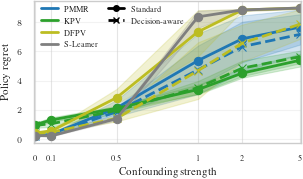

In [37]:
def save_figure(fig: plt.Figure, path: Path) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=220, bbox_inches="tight", facecolor="white")

from typing import Sequence

metric_map = {'regret': 'Policy regret'}
MODE_ORDER = ["Standard", "Decision-aware"]
MODE_MARKERS = {"Standard": "o", "Decision-aware": "x"}
MODE_DASHES = {"Standard": "", "Decision-aware": (4, 2)}


def _split_family_mode(method_name: str) -> tuple[str, str]:
    method_name = str(method_name)
    if method_name.startswith("Weighted "):
        return method_name[len("Weighted "):], "Decision-aware"
    return method_name, "Standard"


def _ordered_families_from_methods(methods: Sequence[str], method_order: Sequence[str] | None = None) -> list[str]:
    observed = []
    for method in methods:
        family, _ = _split_family_mode(str(method))
        if family not in observed:
            observed.append(family)
    if method_order is None:
        return observed
    ordered = []
    for method in method_order:
        family, _ = _split_family_mode(str(method))
        if family in observed and family not in ordered:
            ordered.append(family)
    ordered.extend(family for family in observed if family not in set(ordered))
    return ordered


def _family_color_map(families: Sequence[str], colors: dict[str, str] | None = None) -> dict[str, str]:
    out = {}
    for family in families:
        if colors and family in colors:
            out[family] = colors[family]
        elif colors and f"Weighted {family}" in colors:
            out[family] = colors[f"Weighted {family}"]
        else:
            out[family] = "tab:blue"
    return out


def _confounding_plot_data(
    metrics_df: pd.DataFrame,
    *,
    metric: str,
    split: str,
    methods: Sequence[str] | None,
    seeds: Sequence[int] | None,
) -> pd.DataFrame:
    data = confounding_metric_frame(
        metrics_df,
        metric=metric,
        split=split,
        methods=methods,
        seeds=seeds,
    )
    if data.empty:
        raise ValueError(f"No confounding ablation data for split={split!r}, metric={metric!r}.")
    family_mode = data["method"].astype(str).map(_split_family_mode)
    data = data.copy()
    data["family"] = [family for family, _ in family_mode]
    data["mode"] = [mode for _, mode in family_mode]
    return data


def _double_legend_handles(
    families: Sequence[str],
    color_map: dict[str, str],
    present_modes: Sequence[str],
    labels: dict[str, str] | None = None,
):
    from matplotlib.lines import Line2D

    color_handles = [
        Line2D([0], [0], color=color_map[family], linewidth=2.0, label=labels.get(family, family) if labels else family)
        for family in families
    ]
    mode_handles = [
        Line2D(
            [0],
            [0],
            color="black",
            linewidth=2.0,
            linestyle="--" if mode == "Decision-aware" else "-",
            marker=MODE_MARKERS[mode],
            markersize=4,
            label=mode,
        )
        for mode in MODE_ORDER
        if mode in set(present_modes)
    ]
    return color_handles, mode_handles


def _add_double_legend(
    ax: plt.Axes,
    families: Sequence[str],
    color_map: dict[str, str],
    present_modes: Sequence[str],
    labels: dict[str, str] | None = None,
) -> None:
    color_handles, mode_handles = _double_legend_handles(families, color_map, present_modes, labels)
    if color_handles:
        color_legend = ax.legend(
            handles=color_handles,
            loc="upper left",
            bbox_to_anchor=(0.0, 1.02),
            frameon=False,
            title=None,
        )
        ax.add_artist(color_legend)
    if mode_handles:
        ax.legend(
            handles=mode_handles,
            loc="upper left",
            bbox_to_anchor=(0.25, 1.02),
            frameon=False,
            title=None,
        )


def plot_confounding_metric_ci(
    metrics_df: pd.DataFrame,
    *,
    metric: str = "regret",
    split: str = "test",
    methods: Sequence[str] | None = None,
    method_order: Sequence[str] | None = None,
    colors: dict[str, str] | None = None,
    labels: dict[str, str] | None = None,
    seeds: Sequence[int] | None = None,
    confidence: float = 0.95,
    n_boot: int = 3000,
    ax: plt.Axes | None = None,
    show_legend: bool = True,
) -> plt.Figure:
    data = _confounding_plot_data(
        metrics_df,
        metric=metric,
        split=split,
        methods=methods,
        seeds=seeds,
    )
    family_order = _ordered_families_from_methods(data["method"].dropna().unique(), method_order)
    present_modes = [mode for mode in MODE_ORDER if mode in set(data["mode"].astype(str))]
    color_map = _family_color_map(family_order, colors)
    if ax is None:
        fig, ax = plt.subplots()
    else:
        fig = ax.figure

    sns.lineplot(
        data=data,
        x="confounding_strength",
        y="metric_value",
        hue="family",
        hue_order=family_order,
        palette=color_map,
        style="mode",
        style_order=MODE_ORDER,
        markers=False,
        dashes=False,
        estimator="mean",
        errorbar=("ci", 100.0 * float(confidence)),
        n_boot=int(n_boot),
        linewidth=2.0,
        err_style="band",
        ax=ax,
    )
    auto_legend = ax.get_legend()
    if auto_legend is not None:
        auto_legend.remove()

    line_specs = [
        (family, mode)
        for family in family_order
        for mode in MODE_ORDER
        if not data[(data["family"].astype(str) == family) & (data["mode"].astype(str) == mode)].empty
    ]
    for line, (family, mode) in zip(ax.lines, line_specs):
        line.set_marker(MODE_MARKERS[mode])
        line.set_markersize(6)
        line.set_linestyle("--" if mode == "Decision-aware" else "-")
        line.set_markeredgecolor(color_map[family])      # color correcto
        line.set_markerfacecolor(color_map[family])

    ax.set_xlabel("Confounding strength")
    ax.set_ylabel(metric.capitalize())
    ax.grid(axis="y", alpha=0.25)
    ax.set_xscale('symlog', linthresh=1.0)

    ax.set_xticks([0, 0.1, 0.5, 1.0, 2.0, 5.0])
    ax.set_xticklabels(['0', '0.1', '0.5', '1', '2', '5'])

    ax.set_xlim([-0.01,5.01])

    if show_legend:
        _add_double_legend(ax, family_order, color_map, present_modes, labels)
    return fig

from tueplots import bundles
with plt.rc_context(bundles.icml2024(column='half')):
    fig = plot_confounding_metric_ci(
        metrics_df,
        metric=SELECTED_METRIC,
        split=DEFAULT_SPLIT,
        methods=METHODS_TO_PLOT,
        method_order=METHOD_ORDER,
        colors=METHOD_COLORS,
        labels=METHOD_LABELS,
        seeds=SEEDS_TO_ANALYZE,
        confidence=CONFIDENCE,
        n_boot=N_BOOT,
    )
    ax = fig.axes[0]
    ax.set_ylabel('Policy regret')
    fig.tight_layout()
    if SAVE_FIGURES:
        stem = f"confounding_ablation_{SELECTED_METRIC}_{DEFAULT_SPLIT}"
        save_figure(fig, ANALYSIS_DIR / f"{stem}.png")
        save_figure(fig, ANALYSIS_DIR / f"{stem}.pdf")
    plt.show()


## Common Metrics Panel

Optional panel for quickly checking several metrics with the same selected model subset.

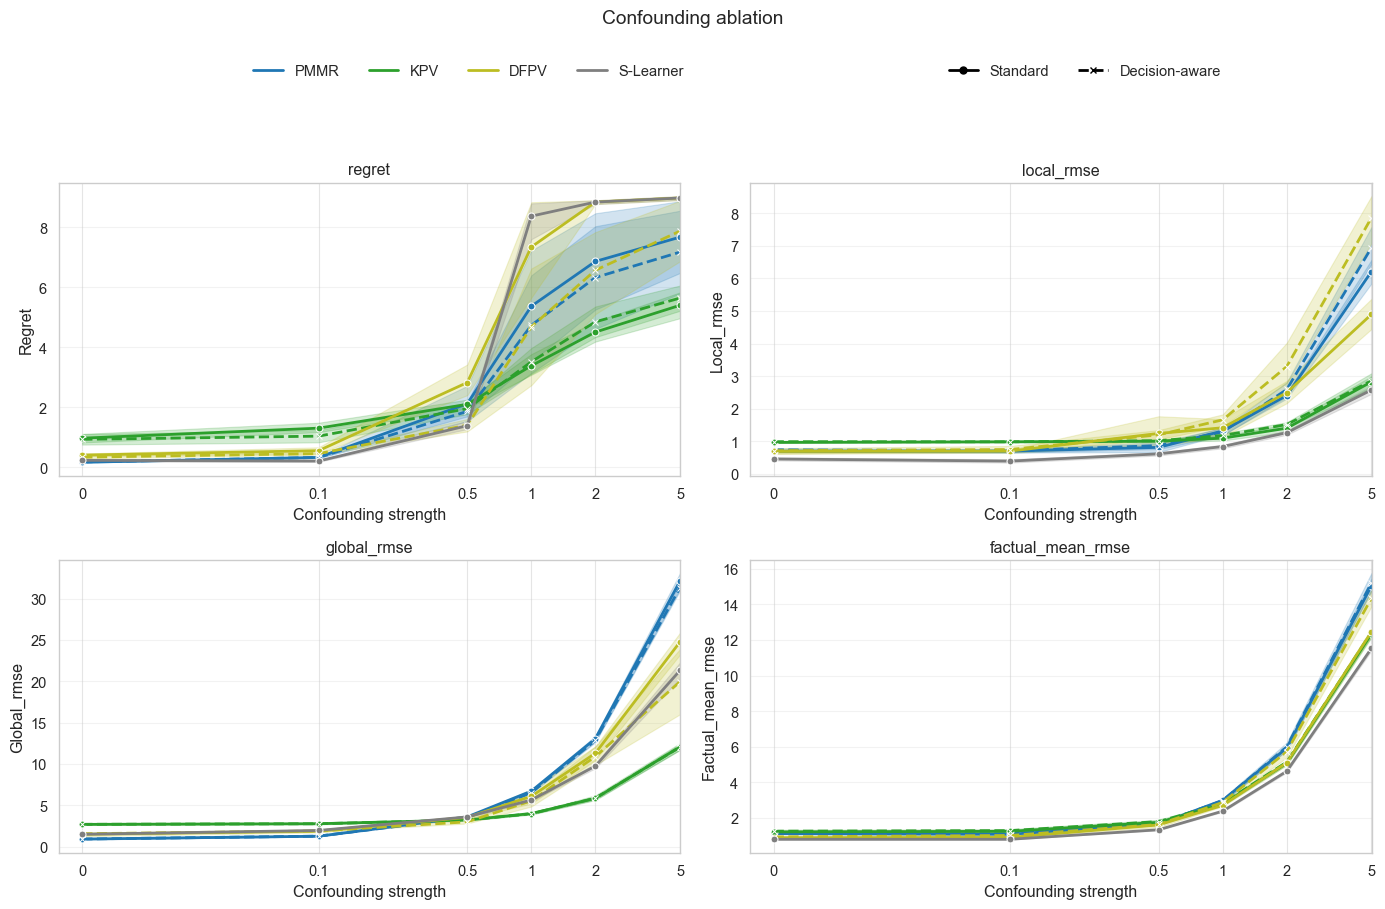

In [28]:
COMMON_METRICS = ["regret", "local_rmse", "global_rmse", "factual_mean_rmse"]
available_common_metrics = [metric for metric in COMMON_METRICS if metric in metrics_df.columns]
if available_common_metrics:
    ncols = 2
    nrows = (len(available_common_metrics) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(7.0 * ncols, 4.2 * nrows), squeeze=False)
    legend_data = None
    for ax, metric in zip(axes.ravel(), available_common_metrics):
        plot_confounding_metric_ci(
            metrics_df,
            metric=metric,
            split=DEFAULT_SPLIT,
            methods=METHODS_TO_PLOT,
            method_order=METHOD_ORDER,
            colors=METHOD_COLORS,
            labels=METHOD_LABELS,
            seeds=SEEDS_TO_ANALYZE,
            confidence=CONFIDENCE,
            n_boot=N_BOOT,
            ax=ax,
            show_legend=False,
        )
        if legend_data is None:
            data_for_legend = _confounding_plot_data(
                metrics_df,
                metric=metric,
                split=DEFAULT_SPLIT,
                methods=METHODS_TO_PLOT,
                seeds=SEEDS_TO_ANALYZE,
            )
            families = _ordered_families_from_methods(data_for_legend["method"].dropna().unique(), METHOD_ORDER)
            modes = [mode for mode in MODE_ORDER if mode in set(data_for_legend["mode"].astype(str))]
            color_map = _family_color_map(families, METHOD_COLORS)
            legend_data = (families, modes, color_map)
        ax.set_title(metric)
    for ax in axes.ravel()[len(available_common_metrics):]:
        ax.axis("off")
    if legend_data is not None:
        families, modes, color_map = legend_data
        color_handles, mode_handles = _double_legend_handles(families, color_map, modes, METHOD_LABELS)
        if color_handles:
            fig.legend(
                handles=color_handles,
                loc="upper center",
                bbox_to_anchor=(0.34, 1.03),
                ncol=min(len(color_handles), 4),
                frameon=False,
                title=None,
            )
        if mode_handles:
            fig.legend(
                handles=mode_handles,
                loc="upper center",
                bbox_to_anchor=(0.78, 1.03),
                ncol=len(mode_handles),
                frameon=False,
                title=None,
            )
    fig.suptitle("Confounding ablation", y=1.08)
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    if SAVE_FIGURES:
        save_figure(fig, ANALYSIS_DIR / f"confounding_ablation_common_metrics_{DEFAULT_SPLIT}.png")
        save_figure(fig, ANALYSIS_DIR / f"confounding_ablation_common_metrics_{DEFAULT_SPLIT}.pdf")
    plt.show()


In [38]:
# Confounding-strength table (rows) x models (columns): mean and variance
conf_table = metrics_df.copy()
if "split" in conf_table.columns:
    conf_table = conf_table[conf_table["split"].astype(str) == str(DEFAULT_SPLIT)].copy()
if METHODS_TO_PLOT is not None:
    conf_table = conf_table[conf_table["method"].isin(METHODS_TO_PLOT)].copy()

conf_table["metric_value"] = pd.to_numeric(conf_table[SELECTED_METRIC], errors="coerce")
conf_table = conf_table.dropna(subset=["confounding_strength", "method", "metric_value"]).copy()

summary_long = (
    conf_table.groupby(["confounding_strength", "method"], observed=True)["metric_value"]
    .agg(mean="mean", var="var")
    .reset_index()
)

method_order_for_table = [m for m in METHOD_ORDER if m in set(summary_long["method"].astype(str))]
method_order_for_table += sorted(
    m for m in summary_long["method"].astype(str).unique() if m not in set(method_order_for_table)
)

summary_long["method"] = pd.Categorical(
    summary_long["method"].astype(str), categories=method_order_for_table, ordered=True
)
summary_long = summary_long.sort_values(["confounding_strength", "method"])

summary_wide = summary_long.pivot(index="confounding_strength", columns="method", values=["mean", "var"])
summary_wide = summary_wide.sort_index(axis=0)
summary_wide = summary_wide.reindex(columns=method_order_for_table, level=1)

print(f"{SELECTED_METRIC} by confounding_strength (mean/var)")
display(summary_wide)


regret by confounding_strength (mean/var)


mean                                                                              var                                                                       
method                    PMMR Weighted PMMR       KPV Weighted KPV      DFPV Weighted DFPV S-Learner      PMMR Weighted PMMR       KPV Weighted KPV      DFPV Weighted DFPV S-Learner
confounding_strength                                                                                                                                                                  
0.0                   0.163902      0.173960  0.966924     0.927857  0.403482      0.332383  0.227717  0.000214      0.000606  0.029202     0.050323  0.003361      0.004520  0.003379
0.1                   0.325700      0.323890  1.300680     1.034391  0.549437      0.452641  0.203461  0.000703      0.000511  0.039784     0.073273  0.018119      0.002354  0.001103
0.5                   2.115150      1.859891  2.094881     1.949788  2.822080      1.399105  1.382848  0.413319      0.172798  0.037625     0.058153  0.462249      0.071607  0.029983
1.0                   5.366606      4.730422  3.382629     3.513023  7.340322      4.678028  8.369473  5.436869      4.376350  0.201670     0.326603  4.215738      6.147345  0.724656
2.0                   6.859831      6.322223  4.502967     4.845322  8.839093      6.565827  8.839093  4.255531      4.792753  0.199211     0.484588  0.006310      3.104535  0.006310
5.0                   7.670113      7.170389  5.397142     5.638243  8.975331      7.871811  8.975331  2.473739      3.227117  0.310201     0.309860  0.006444      1.657091  0.006444